# MLB 팀 기록으로 본 "승리는 어디서 오는가"

Lahman Baseball Database(1871–2015)의 팀 시즌 기록으로 세 가지 질문을 확인합니다.

1. 득점과 실점만으로 승률을 얼마나 맞출 수 있을까? — 피타고리안 기대승률
2. 타율·출루율·장타율·OPS 중 득점을 가장 잘 설명하는 지표는?
3. 연봉으로 승리를 살 수 있을까?

분석 범위: 1985–2015년(연봉 데이터가 있는 기간). 파업으로 시즌이 짧았던 1994년은 제외했습니다.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'Malgun Gothic'   # 한글 폰트 (macOS는 'AppleGothic')
plt.rcParams['axes.unicode_minus'] = False

teams = pd.read_csv('data/Teams.csv')
t = teams[(teams.yearID >= 1985) & (teams.yearID <= 2015) & (teams.yearID != 1994)].copy()
t['wpct'] = t.W / (t.W + t.L)
print(f'팀 시즌 {len(t)}개, {t.yearID.min()}–{t.yearID.max()}')

팀 시즌 860개, 1985–2015


## 1. 득점과 실점만으로 승률을 맞출 수 있을까

빌 제임스의 **피타고리안 기대승률** `승률 ≈ 득점^k / (득점^k + 실점^k)`에서 지수 k를 0.01 단위로 바꿔 가며 실제 승률과의 오차(RMSE)가 가장 작은 값을 찾습니다.

최적 지수 k = 1.90, 162경기 기준 오차 ±3.9승
경기당 득실차가 설명하는 승률 변동 R² = 0.871
1승을 더 하려면 득실차 약 9.8점이 필요


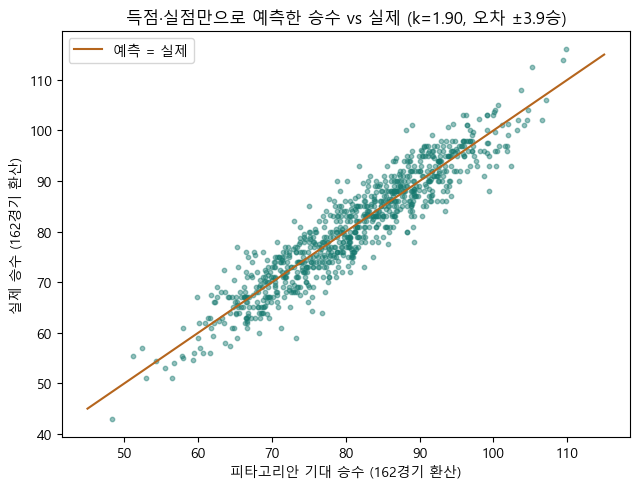

In [2]:
ks = np.arange(1.5, 2.6, 0.01)
rmse = [np.sqrt((((t.R**k)/(t.R**k + t.RA**k) - t.wpct)**2).mean()) for k in ks]
best_k = ks[int(np.argmin(rmse))]
t['pyth'] = t.R**best_k / (t.R**best_k + t.RA**best_k)
r2 = np.corrcoef((t.R - t.RA) / t.G, t.wpct)[0, 1]**2
runs_per_win = 1 / np.polyfit(t.R - t.RA, t.W / t.G * 162, 1)[0]
print(f'최적 지수 k = {best_k:.2f}, 162경기 기준 오차 ±{min(rmse)*162:.1f}승')
print(f'경기당 득실차가 설명하는 승률 변동 R² = {r2:.3f}')
print(f'1승을 더 하려면 득실차 약 {runs_per_win:.1f}점이 필요')

fig, ax = plt.subplots(figsize=(6.5, 5))
ax.scatter(t.pyth * 162, t.wpct * 162, s=10, alpha=0.45, color='#16796f')
ax.plot([45, 115], [45, 115], color='#b5651d', lw=1.5, label='예측 = 실제')
ax.set_xlabel('피타고리안 기대 승수 (162경기 환산)'); ax.set_ylabel('실제 승수 (162경기 환산)')
ax.set_title(f'득점·실점만으로 예측한 승수 vs 실제 (k={best_k:.2f}, 오차 ±{min(rmse)*162:.1f}승)')
ax.legend(); plt.tight_layout(); plt.savefig('images/01_pythagorean.png', dpi=150); plt.show()

**결과**: 경기당 득실차가 승률 변동의 약 87%를 설명합니다. 최적 지수는 1.90으로 빌 제임스가 제안한 2와 거의 같고, 오차는 한 시즌 ±4승 정도입니다. 득실차 약 10점이 1승에 해당합니다.

→ 그렇다면 **득점은 무엇이 만드는가**를 다음 질문에서 봅니다.

## 2. 득점을 가장 잘 설명하는 공격 지표는?

희생플라이(SF)·사구(HBP)가 모든 팀에 기록된 **2000–2015년 480개 팀 시즌**으로 범위를 좁혀, 각 지표와 경기당 득점의 결정계수(R²)를 비교합니다.

{'AVG': np.float64(0.664), 'OBP': np.float64(0.806), 'SLG': np.float64(0.84), 'OPS': np.float64(0.913)}
경기당 득점 ≈ -5.33 + 16.59×OBP + 10.73×SLG
출루율 1포인트는 장타율 1포인트보다 득점에 1.55배 기여


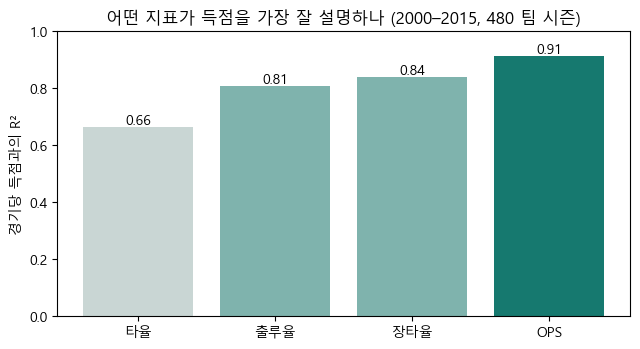

In [3]:
o = teams[(teams.yearID >= 2000) & (teams.yearID <= 2015)].copy()
o['1B'] = o.H - o['2B'] - o['3B'] - o.HR
o['AVG'] = o.H / o.AB
o['OBP'] = (o.H + o.BB + o.HBP) / (o.AB + o.BB + o.HBP + o.SF)
o['SLG'] = (o['1B'] + 2*o['2B'] + 3*o['3B'] + 4*o.HR) / o.AB
o['OPS'] = o.OBP + o.SLG
o['RPG'] = o.R / o.G
r2s = {c: np.corrcoef(o[c], o.RPG)[0, 1]**2 for c in ['AVG', 'OBP', 'SLG', 'OPS']}
print({k: round(v, 3) for k, v in r2s.items()})

X = np.column_stack([np.ones(len(o)), o.OBP, o.SLG])
coef, *_ = np.linalg.lstsq(X, o.RPG, rcond=None)
print(f'경기당 득점 ≈ {coef[0]:.2f} + {coef[1]:.2f}×OBP + {coef[2]:.2f}×SLG')
print(f'출루율 1포인트는 장타율 1포인트보다 득점에 {coef[1]/coef[2]:.2f}배 기여')

fig, ax = plt.subplots(figsize=(6.5, 3.6))
names = {'AVG': '타율', 'OBP': '출루율', 'SLG': '장타율', 'OPS': 'OPS'}
bars = ax.bar([names[k] for k in r2s], list(r2s.values()), color=['#c9d6d4', '#7fb3ad', '#7fb3ad', '#16796f'])
for b, v in zip(bars, r2s.values()): ax.text(b.get_x() + b.get_width()/2, v + 0.01, f'{v:.2f}', ha='center')
ax.set_ylim(0, 1); ax.set_ylabel('경기당 득점과의 R²')
ax.set_title('어떤 지표가 득점을 가장 잘 설명하나 (2000–2015, 480 팀 시즌)')
plt.tight_layout(); plt.savefig('images/02_offense_r2.png', dpi=150); plt.show()

**결과**: 전통적으로 많이 쓰는 **타율(R² 0.66)보다 출루율(0.81)과 장타율(0.84)이 득점을 더 잘 설명**하고, 둘을 더한 **OPS가 0.91로 가장 좋습니다**. 두 지표로 회귀하면 출루율 1포인트의 가치가 장타율 1포인트의 약 1.5배입니다 — 영화 「머니볼」에서 오클랜드가 출루율에 주목한 이유와 같은 결론입니다.

## 3. 연봉으로 승리를 살 수 있을까

해마다 리그 전체 연봉 수준이 크게 달라서, 팀 연봉을 **그해 리그 평균 대비 비율**로 바꿔 비교합니다.

상대 연봉과 승률: 상관계수 r = 0.37, R² = 0.13
        평균승수 포스트시즌진출률
q                    
하위 25%  75.8      12%
25–50%  79.0      19%
50–75%  83.1      27%
상위 25%  86.1      41%
 yearID              name   W  L  rel_pay
   2002 Oakland Athletics 103 59     0.59
   2001 Oakland Athletics 102 60     0.52
   2008    Tampa Bay Rays  97 65     0.49
   2013 Oakland Athletics  96 66     0.59
   2000 Chicago White Sox  95 67     0.56


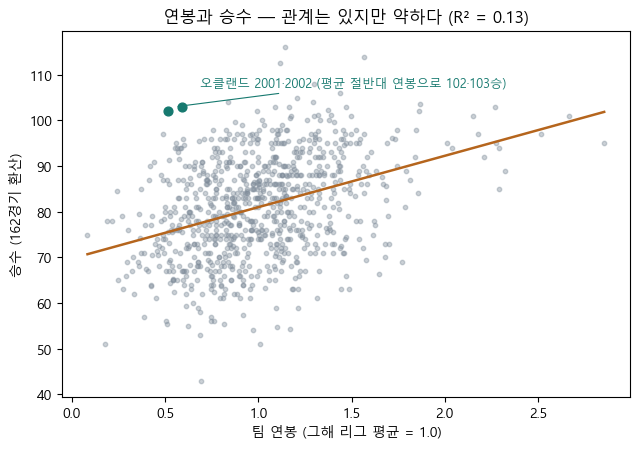

In [4]:
sal = pd.read_csv('data/Salaries.csv')
pay = sal.groupby(['yearID', 'teamID']).salary.sum().reset_index()
m = t.merge(pay, on=['yearID', 'teamID'])
m['rel_pay'] = m.salary / m.groupby('yearID').salary.transform('mean')
r = np.corrcoef(m.rel_pay, m.wpct)[0, 1]
print(f'상대 연봉과 승률: 상관계수 r = {r:.2f}, R² = {r*r:.2f}')

m['q'] = pd.qcut(m.rel_pay, 4, labels=['하위 25%', '25–50%', '50–75%', '상위 25%'])
m['postseason'] = (m.DivWin == 'Y') | (m.WCWin == 'Y')
summary = m.groupby('q', observed=True).agg(평균승수=('wpct', lambda x: round(x.mean()*162, 1)),
                                           포스트시즌진출률=('postseason', lambda x: f'{x.mean():.0%}'))
print(summary)
print(m[m.rel_pay < 0.6].nlargest(5, 'wpct')[['yearID', 'name', 'W', 'L', 'rel_pay']].round(2).to_string(index=False))

fig, ax = plt.subplots(figsize=(6.5, 4.6))
ax.scatter(m.rel_pay, m.wpct * 162, s=10, alpha=0.4, color='#7f8c9a')
b = np.polyfit(m.rel_pay, m.wpct * 162, 1)
xs = np.linspace(m.rel_pay.min(), m.rel_pay.max(), 50); ax.plot(xs, np.polyval(b, xs), color='#b5651d', lw=1.8)
oak = m[(m.teamID == 'OAK') & (m.yearID.isin([2001, 2002]))]
ax.scatter(oak.rel_pay, oak.wpct * 162, s=40, color='#16796f', zorder=3)
ax.annotate('오클랜드 2001·2002 (평균 절반대 연봉으로 102·103승)', (oak.rel_pay.mean(), oak.wpct.max()*162), xytext=(18, 14), textcoords='offset points', fontsize=9, color='#16796f', arrowprops=dict(arrowstyle='-', color='#16796f', lw=0.8))
ax.set_xlabel('팀 연봉 (그해 리그 평균 = 1.0)'); ax.set_ylabel('승수 (162경기 환산)')
ax.set_title(f'연봉과 승수 — 관계는 있지만 약하다 (R² = {r*r:.2f})')
plt.tight_layout(); plt.savefig('images/03_payroll_wins.png', dpi=150); plt.show()

**결과**: 연봉이 많은 팀이 더 이기는 경향은 분명합니다. 상위 25% 팀은 평균 86승에 포스트시즌 진출률이 41%이고, 하위 25% 팀은 76승에 12%입니다. 하지만 **연봉이 승률 변동을 설명하는 비율은 13%뿐**입니다. 리그 평균의 절반 정도 연봉으로 103승을 거둔 2002년 오클랜드처럼, 돈보다 **득점·실점을 만드는 선수를 고르는 방식**이 더 큰 차이를 만듭니다.

## 정리

| 질문 | 답 |
|---|---|
| 승률은 무엇으로 결정되나 | 득실차가 87% 설명. 약 10점 = 1승 |
| 득점은 무엇이 만드나 | OPS(R² 0.91) > 장타율 > 출루율 > 타율. 출루율 1포인트 ≈ 장타율 1.5포인트 |
| 연봉으로 승리를 사나 | 경향은 있지만 설명력 13%. 효율적인 팀 구성이 더 중요 |

**한계**: 팀 단위 집계라 선수 개인의 기여는 보지 않았고, 수비·구장 효과는 고려하지 않았습니다. 다음 단계로는 선수 단위 데이터(Batting.csv)로 "연봉 대비 OPS가 높은 선수"를 찾아보고 싶습니다.